 # TODO:



*   Splitting dataset for train,test and val
  



In [ ]:
from collections.abc import Callable
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from sklearn.model_selection import train_test_split  # Added train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset, Subset  # Added Subset
from torchvision import transforms

from dlvr.unet_model import UNet
from dlvr.simple_crack_dataset import SimpleCrackDataset

In [3]:
## loading dataset path
cwd = Path.cwd().parents[1].absolute()
print(cwd)
deepcrack_dataset_path = [ds for ds in cwd.glob("data/deepcrack*/**")][1]
print(deepcrack_dataset_path)

/home/jes/proj/DLVR
/home/jes/proj/DLVR/data/deepcrack_dataset-20260929T192456Z-1-001/deepcrack_dataset


## Pytorch dataset object

Define dataset object for correct handling of test and train data

In [5]:
# Define the target path in Google Drive for persistent storage
# The dataset is expected to be here, making it accessible across sessions and shareable.
gdrive_dataset_path = (
    deepcrack_dataset_path  # Assuming the dataset is already in the 'data' directory
)

if gdrive_dataset_path.exists():
    print(*gdrive_dataset_path.glob("*"), sep="\n")

/home/jes/proj/DLVR/data/deepcrack_dataset-20260929T192456Z-1-001/deepcrack_dataset/test_lab
/home/jes/proj/DLVR/data/deepcrack_dataset-20260929T192456Z-1-001/deepcrack_dataset/README.md
/home/jes/proj/DLVR/data/deepcrack_dataset-20260929T192456Z-1-001/deepcrack_dataset/train_img
/home/jes/proj/DLVR/data/deepcrack_dataset-20260929T192456Z-1-001/deepcrack_dataset/train_lab
/home/jes/proj/DLVR/data/deepcrack_dataset-20260929T192456Z-1-001/deepcrack_dataset/test_img


### Define dataset transformations

In [6]:
data_transform = transforms.Compose(
    [
        transforms.Resize((384, 544)),  # Resize to a consistent size
        transforms.ToTensor(),
        # Normalizing images to ImageNet stats, commonly used for transfer learning models
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ]
)

target_transform = transforms.Compose(
    [
        transforms.Resize((384, 544)),  # Resize masks to a consistent size
        transforms.ToTensor(),
    ]
)

### Load training data

In [7]:
full_train_dataset = SimpleCrackDataset(
    gdrive_dataset_path,
    mode="train",
    transform=data_transform,
    target_transform=target_transform,
)

## Load Test data

In [ ]:
test_dataset = SimpleCrackDataset(
    gdrive_dataset_path,
    mode="test",
    transform=data_transform,
    target_transform=target_transform,
)


## Spliting Train for Train and Validation dataset

In [9]:
train_indices, val_indices = train_test_split(
    list(range(len(full_train_dataset))), test_size=0.20, random_state=42
)

train_dataset = Subset(full_train_dataset, train_indices)
val_dataset = Subset(full_train_dataset, val_indices)

In [10]:
train_loader = DataLoader(
    train_dataset, batch_size=4, shuffle=True, num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=4, shuffle=False, num_workers=2, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=4, shuffle=False, num_workers=2, pin_memory=True
)

## check image stats

In [ ]:
def check_tensor_stats(loader, n_batches=5):
    """
    Check the mean and std of pixel values after normalisation.
    After ImageNet normalisation, mean should be near 0 and std near 1.
    Large deviations suggest the wrong normalisation was applied.
    """
    all_means = []
    all_stds = []

    for i, (images, _) in enumerate(loader):
        if i >= n_batches:
            break
        all_means.append(images.mean(dim=[0, 2, 3]).numpy())  # per channel
        all_stds.append(images.std(dim=[0, 2, 3]).numpy())

    mean = np.array(all_means).mean(axis=0)
    std = np.array(all_stds).mean(axis=0)

    print("After normalisation (should be near mean≈0, std≈1 per channel):")
    for c, name in enumerate(["R", "G", "B"]):
        print(f"  {name}: mean={mean[c]:.3f}, std={std[c]:.3f}")

    if abs(mean).max() > 0.5:
        print("WARNING: Mean far from 0 — check normalisation values.")
    if abs(std - 1).max() > 0.5:
        print("WARNING: Std far from 1 — check normalisation values.")


# Check one batch
images, masks = next(iter(train_loader))
print(f"Batch image shape: {images.shape}")  # (32, 3, 224, 224)
print(f"Batch masks shape: {masks.shape}")  # (32,)

check_tensor_stats(train_loader)

/home/jes/proj/DLVR/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


### Visualize random selection of the data

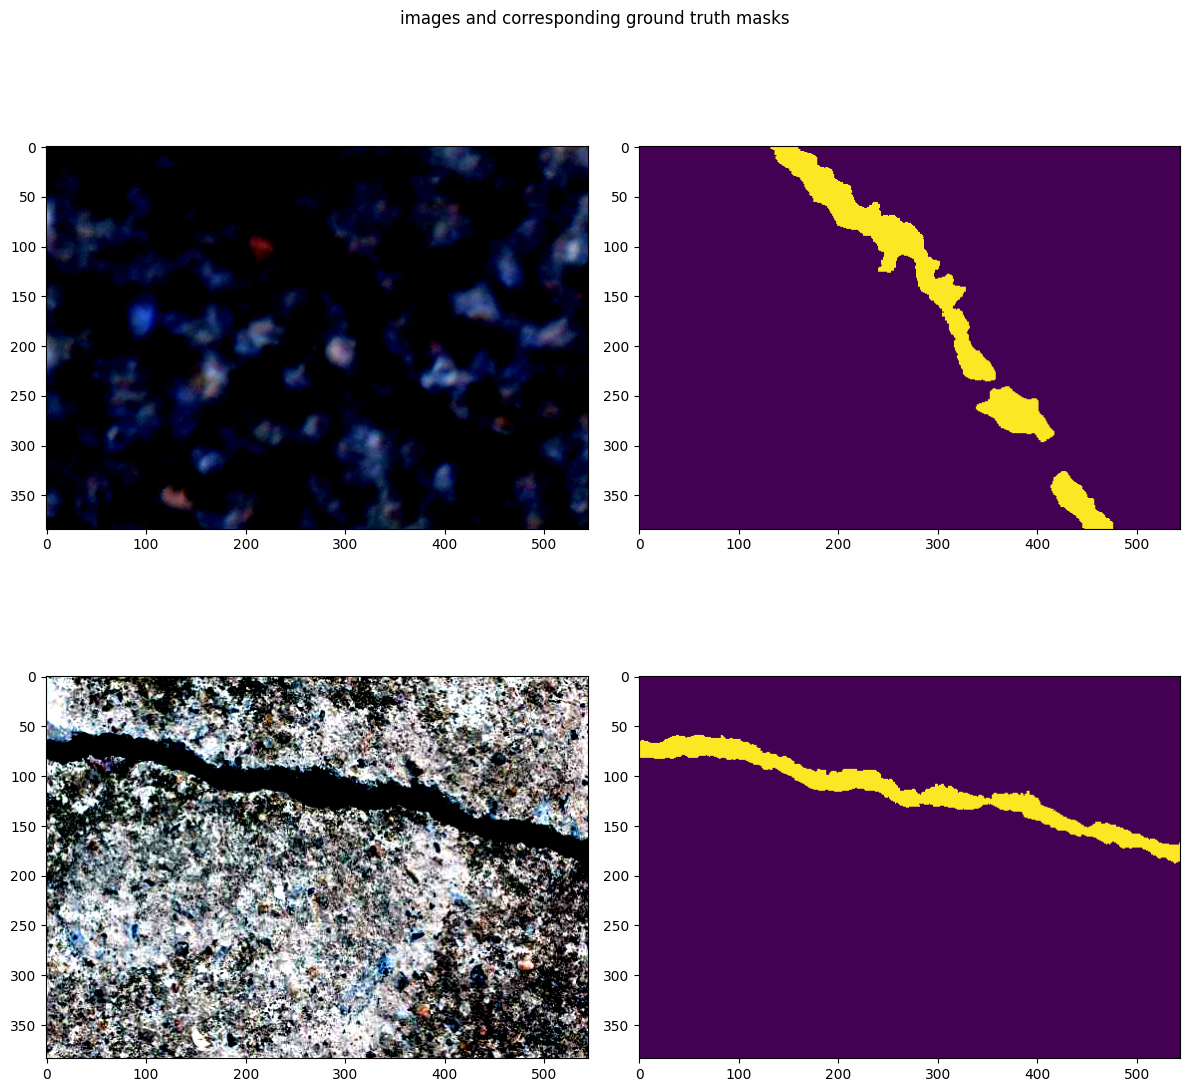

In [ ]:
def visualise_samples(dataset, n=4):
    """
    Show n examples.
    The most important sanity check — do the images and labels look right?
    """
    fig, axes = plt.subplots(n, 2, figsize=(n * 6, n * 6))

    for i in range(n):
        indx = np.random.randint(0, len(dataset))
        ax_img = axes[i][0]
        ax_mask = axes[i][1]
        ax_img.imshow(
            dataset[indx][0].permute(1, 2, 0),
        )
        ax_mask.imshow(dataset[indx][1].permute(1, 2, 0))

    plt.suptitle("images and corresponding ground truth masks", fontsize=12)
    plt.tight_layout()
    plt.show()


visualise_samples(train_dataset, 2)

### Loss Function

In [ ]:
from dlvr.loss_functions import BCELoss
from dlvr.metrics import IoU

### Defining

In [ ]:
from torch import optim

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Defining model
model = UNet(in_channels=3, n_class=1).to(device)

# Adam optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Calling loss function
loss_function = BCELoss()

### Training Loop

In [ ]:
NUM_EPOCHS = 15

best_val_iou = 0
train_losses = []
val_losses = []
train_ious = []
val_ious = []

for epoch in range(NUM_EPOCHS):
    model.train()

    train_loss = 0
    train_iou = 0

    # Clear CUDA cache before each epoch to free up memory
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)
        optimizer.zero_grad()

        # forward pass
        outputs = model(images)
        loss = loss_function(outputs, masks)

        # we need also backward
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_iou += IoU(outputs, masks)

    avg_train_loss = train_loss / len(train_loader)
    avg_train_iou = train_iou / len(train_loader)
    train_losses.append(avg_train_loss)
    train_ious.append(avg_train_iou)
    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS}, Train Loss: {avg_train_loss:.4f}, Train IoU: {avg_train_iou:.4f}"
    )

    # Validation Phase
    model.eval()
    val_loss = 0
    val_iou = 0
    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)
            loss = loss_function(outputs, masks)

            val_loss += loss.item()
            val_iou += IoU(outputs, masks)

    avg_val_loss = val_loss / len(val_loader)
    avg_val_iou = val_iou / len(val_loader)
    val_losses.append(avg_val_loss)
    val_ious.append(avg_val_iou)
    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS}, Val Loss: {avg_val_loss:.4f}, Val IoU: {avg_val_iou:.4f}"
    )

    if avg_val_iou > best_val_iou:
        best_val_iou = avg_val_iou
        torch.save(model.state_dict(), "best_unet_baseline.pth")
        print(f"--> Saved new best model with Val IoU : {best_val_iou:.4f}")

Epoch 1/15, Train Loss: 0.3301, Train IoU: 0.3684
Epoch 1/15, Val Loss: 0.0799, Val IoU: 0.4767
--> Saved new best model with Val IoU : 0.4767
Epoch 2/15, Train Loss: 0.0737, Train IoU: 0.4440
Epoch 2/15, Val Loss: 0.0489, Val IoU: 0.5102
--> Saved new best model with Val IoU : 0.5102
Epoch 3/15, Train Loss: 0.0532, Train IoU: 0.5062
Epoch 3/15, Val Loss: 0.0482, Val IoU: 0.4034
Epoch 4/15, Train Loss: 0.0516, Train IoU: 0.4843
Epoch 4/15, Val Loss: 0.0471, Val IoU: 0.5247
--> Saved new best model with Val IoU : 0.5247
Epoch 5/15, Train Loss: 0.0550, Train IoU: 0.4726
Epoch 5/15, Val Loss: 0.0472, Val IoU: 0.4599
Epoch 6/15, Train Loss: 0.0497, Train IoU: 0.5100
Epoch 6/15, Val Loss: 0.0433, Val IoU: 0.4706
Epoch 7/15, Train Loss: 0.0485, Train IoU: 0.5275
Epoch 7/15, Val Loss: 0.0551, Val IoU: 0.3241
Epoch 8/15, Train Loss: 0.0468, Train IoU: 0.5221
Epoch 8/15, Val Loss: 0.0446, Val IoU: 0.5106
Epoch 9/15, Train Loss: 0.0474, Train IoU: 0.5349
Epoch 9/15, Val Loss: 0.0488, Val IoU: 0.

Plotting metrics

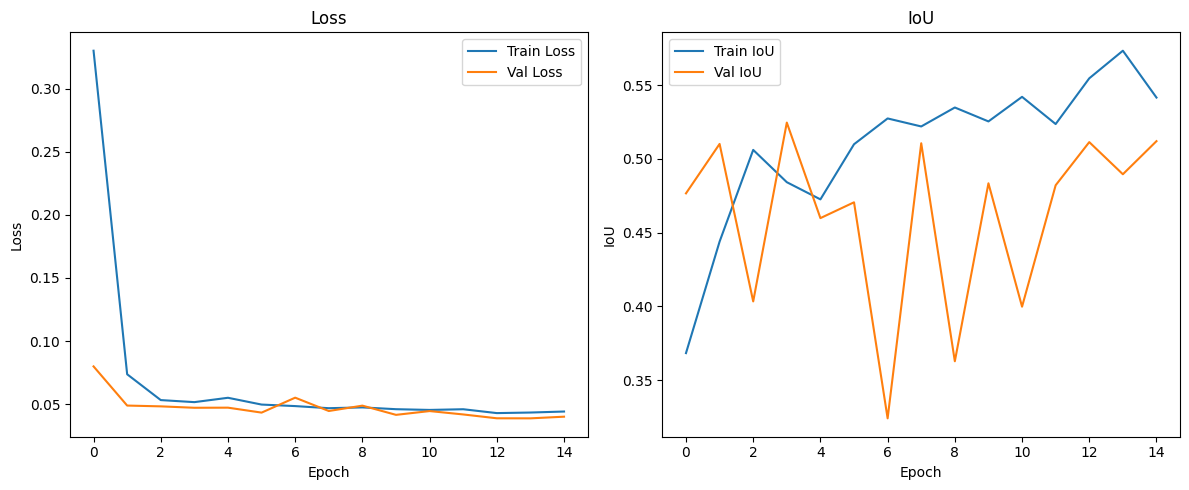

In [ ]:
plt.figure(figsize=(12, 5))

# Graph for Loss
plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()

# Graph for IoU
plt.subplot(1, 2, 2)
plt.plot(train_ious, label="Train IoU")
plt.plot(val_ious, label="Val IoU")
plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.title("IoU")
plt.legend()

plt.tight_layout()
plt.show()

### Test

In [ ]:
model.load_state_dict(torch.load("best_unet_baseline.pth"))
model.eval()

test_loss = 0.0
test_iou = 0.0

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)
        l = loss_function(outputs, masks)

        test_loss += l.item()
        test_iou += IoU(outputs, masks)

final_test_loss = test_loss / len(test_loader)
final_test_iou = test_iou / len(test_loader)

print(f"Final Test Loss: {final_test_loss:.4f}")
print(f"Final Test IoU: {final_test_iou:.4f}")

Final Test Loss: 0.0675
Final Test IoU: 0.5504


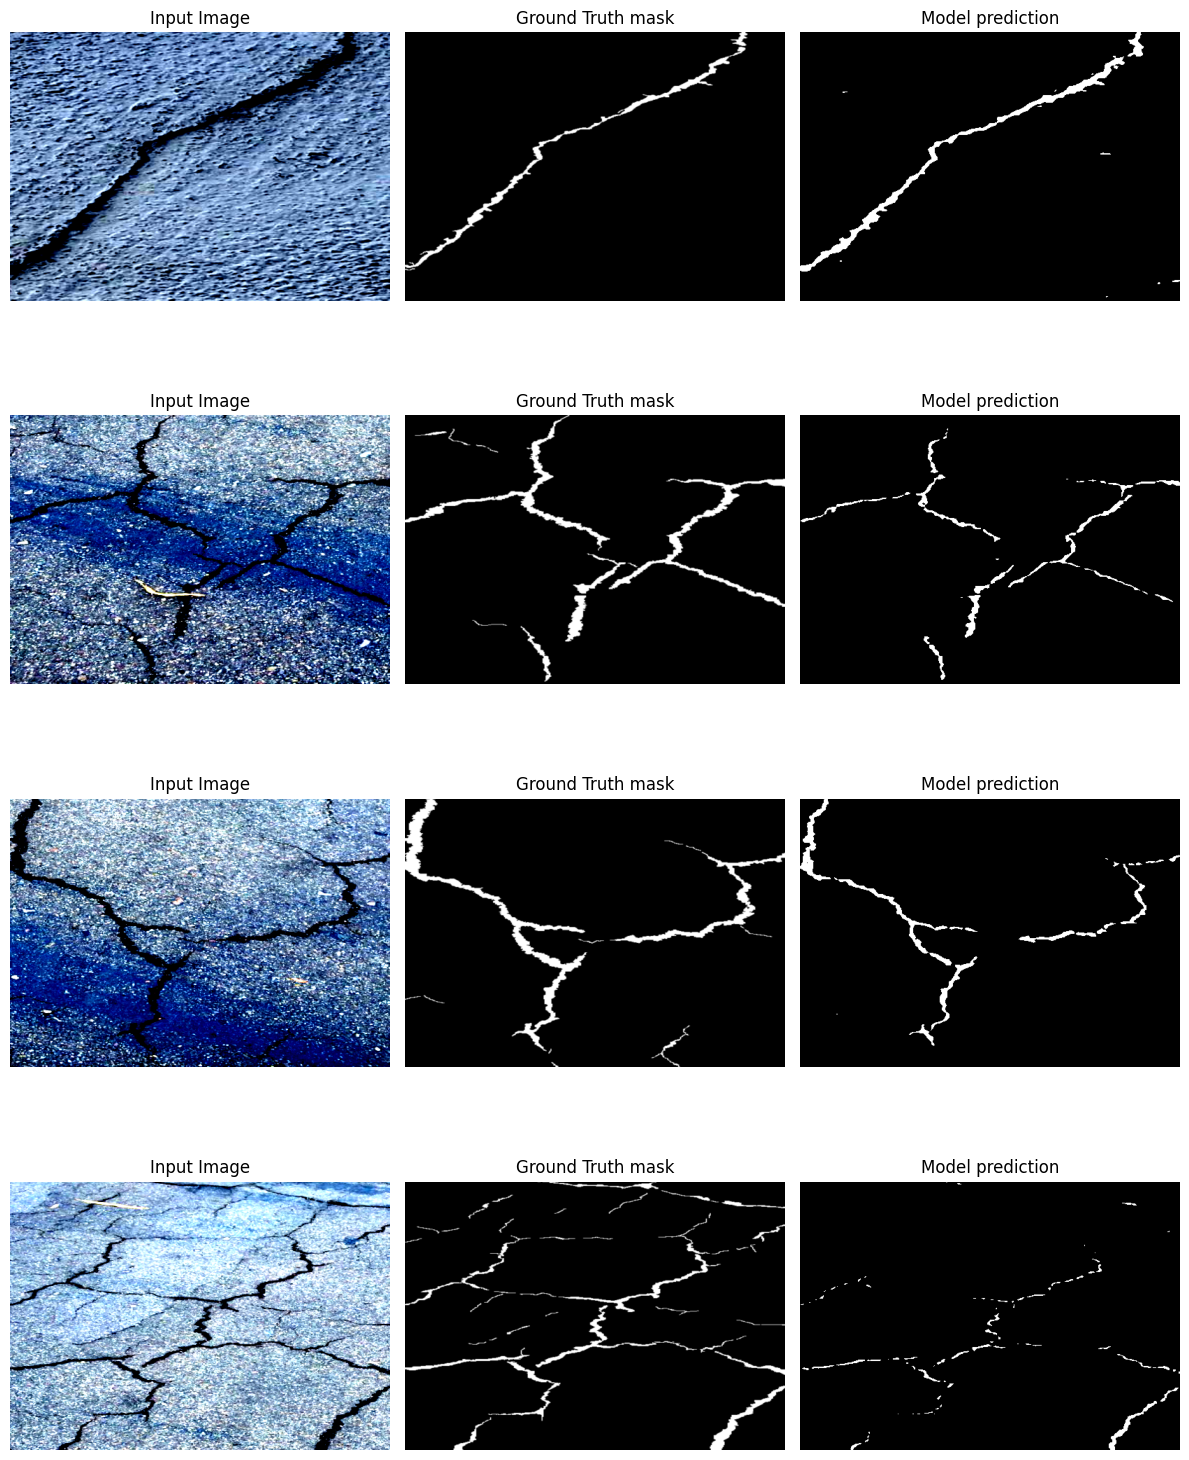

In [ ]:
def vizualize_test_predictions(model, test_loader, n_samples=4):
    model.eval()
    images, masks = next(iter(test_loader))
    images = images.to(device)

    with torch.no_grad():
        logits = model(images)
        probs = torch.sigmoid(logits)
        preds = (probs > 0.5).float()

    images = images.cpu()
    masks = masks.cpu()
    preds = preds.cpu()

    fig, axes = plt.subplots(n_samples, 3, figsize=(12, n_samples * 4))

    for i in range(n_samples):
        # Image(re-permutation from [C, H, W] on [H, W, C])
        img = images[i].permute(1, 2, 0).numpy()
        # Denormalization
        img = np.clip(img, 0, 1)

        axes[i, 0].imshow(img)
        axes[i, 0].set_title("Input Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(masks[i].squeeze(), cmap="gray")
        axes[i, 1].set_title("Ground Truth mask")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(preds[i].squeeze(), cmap="gray")
        axes[i, 2].set_title("Model prediction")
        axes[i, 2].axis("off")

    plt.tight_layout()
    plt.show()


vizualize_test_predictions(model, test_loader, n_samples=4)